# Bài tập 1 - LeNet trên MNIST và phân tích biến thể

**Học viên:** Nguyễn Đăng Thới Toàn  
**Mã số học viên:** 25C15062

## Mục tiêu

Cài đặt LeNet, so sánh vai trò của hàm kích hoạt, pooling và tầng convolution thứ hai. Đánh giá thêm độ bền vững trước nhiễu ảnh và khả năng chuyển sang bộ chữ số viết tay EMNIST Digits.

Các bảng, hình và nhận xét định lượng được tạo từ số liệu ngay trong notebook khi thực hiện các ô theo thứ tự.

## Thiết kế thực nghiệm

| Yếu tố | Thiết kế |
|---|---|
| Dữ liệu chính | MNIST: 50.000 ảnh train, 10.000 validation, 10.000 test; chia train/validation cố định |
| Số lần lặp | 5 seed: 42–46; thay đổi khởi tạo mô hình, thứ tự ảnh và augmentation, giữ nguyên cách chia dữ liệu |
| Cấu hình so sánh | 3 epoch, Adam với learning rate 0,001, batch 128; cùng thiết lập cho mọi kiến trúc |
| Các kiến trúc | LeNet tanh/average pooling (đối chứng); ReLU; max pooling; bỏ convolution thứ hai |
| Mở rộng 1 | Tăng cường dữ liệu bằng xoay ±15° và Gaussian noise σ=0,15 khi huấn luyện |
| Mở rộng 2 | Đánh giá trên ảnh MNIST bị nhiễu, xoay, làm mờ; so sánh với EMNIST Digits không dùng để huấn luyện |
| Chỉ số | Accuracy trung bình ± độ lệch chuẩn, mức suy giảm theo điểm phần trăm, thời gian huấn luyện và latency suy luận |

Tập test không dùng để cập nhật tham số. Năm seed giúp quan sát biến thiên do huấn luyện; kết quả vẫn gắn với **một phép chia dữ liệu cố định**. Độ lệch chuẩn trong các bảng là độ lệch chuẩn mẫu của 5 seed.

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.transforms import InterpolationMode
from torchvision.transforms import functional as TF

In [2]:
SPLIT_SEED = 42
SEEDS = (42, 43, 44, 45, 46)
BATCH_SIZE = 128
EPOCHS = 3
CONVERGENCE_EPOCHS = 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(SPLIT_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print(f"PyTorch {torch.__version__}; thiết bị: {DEVICE}")
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name())

PyTorch 2.7.0+cu128; thiết bị: cuda
NVIDIA GeForce RTX 5090


## 1. Chuẩn bị dữ liệu

Ảnh MNIST kích thước 28×28 được pad thành 32×32 để phù hợp cấu trúc LeNet. Augmentation chỉ áp dụng lên train của mô hình mở rộng; validation và test luôn dùng ảnh không biến đổi. Tập train/validation được chia một lần bằng `SPLIT_SEED`, độc lập với năm seed huấn luyện.

### 1.1. Biến đổi ảnh

In [3]:
class AddGaussianNoise:
    def __init__(self, sigma: float = 0.15):
        self.sigma = sigma

    def __call__(self, image: torch.Tensor) -> torch.Tensor:
        noise = torch.randn_like(image) * self.sigma
        return (image + noise).clamp(0, 1)


plain_transform = transforms.Compose(
    [
        transforms.Pad(2),
        transforms.ToTensor(),
    ]
)
augmented_transform = transforms.Compose(
    [
        transforms.Pad(2),
        transforms.RandomRotation(15),
        transforms.ToTensor(),
        AddGaussianNoise(0.15),
    ]
)

### 1.2. Chia dữ liệu

In [4]:
train_plain = datasets.MNIST(
    "data", train=True, download=True, transform=plain_transform
)
train_augmented = datasets.MNIST(
    "data", train=True, download=False, transform=augmented_transform
)
test_data = datasets.MNIST(
    "data", train=False, download=True, transform=plain_transform
)

indices = np.random.default_rng(SPLIT_SEED).permutation(len(train_plain))
train_indices = indices[:50_000].tolist()
val_indices = indices[50_000:].tolist()

### 1.3. DataLoader

In [5]:
def make_loader(dataset, indices=None, shuffle=False, seed=None):
    selected = Subset(dataset, indices) if indices is not None else dataset
    if shuffle and seed is None:
        raise ValueError("Cần seed khi shuffle train")
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(
        selected,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=generator,
        num_workers=2,
        pin_memory=DEVICE.type == "cuda",
    )


val_loader = make_loader(train_plain, val_indices)
test_loader = make_loader(test_data)
print(
    f"Train: {len(train_indices):,}; validation: {len(val_indices):,}; "
    f"test: {len(test_data):,}"
)

Train: 50,000; validation: 10,000; test: 10,000


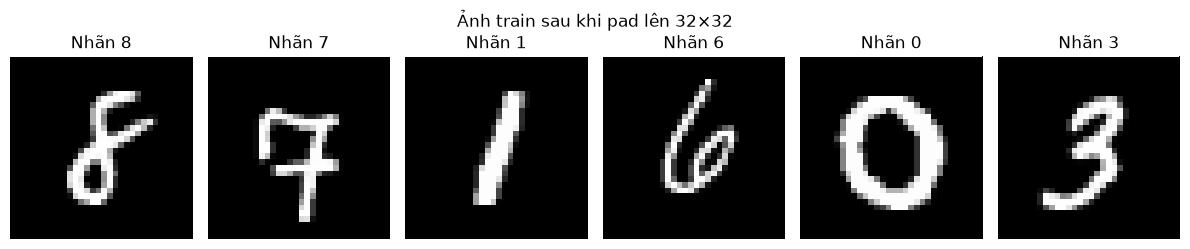

In [6]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2.5))
for axis, index in zip(axes, train_indices[:6], strict=True):
    image, label = train_plain[index]
    axis.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
    axis.set_title(f"Nhãn {label}")
    axis.axis("off")
plt.suptitle("Ảnh train sau khi pad lên 32×32")
plt.tight_layout()
plt.show()

## 2. Kiến trúc và quy trình huấn luyện

Mô hình đối chứng dùng `tanh` và average pooling. Mỗi biến thể chỉ thay một thành phần kiến trúc. Khi bỏ tầng convolution thứ hai, số tham số của bộ phân loại cũng thay đổi; vì vậy đây là so sánh **toàn kiến trúc**, không phải phép đo tác động cô lập của một tầng.

In [7]:
class LeNet(nn.Module):
    def __init__(self, activation="tanh", pooling="avg", skip_conv2=False):
        super().__init__()
        activation_layer = nn.Tanh if activation == "tanh" else nn.ReLU
        pooling_layer = nn.AvgPool2d if pooling == "avg" else nn.MaxPool2d

        layers = [nn.Conv2d(1, 6, kernel_size=5), activation_layer(), pooling_layer(2)]
        if not skip_conv2:
            layers.extend([nn.Conv2d(6, 16, kernel_size=5), activation_layer()])
        layers.append(pooling_layer(2))
        self.features = nn.Sequential(*layers)

        with torch.no_grad():
            flat_features = self.features(torch.zeros(1, 1, 32, 32)).numel()
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_features, 120),
            activation_layer(),
            nn.Linear(120, 84),
            activation_layer(),
            nn.Linear(84, 10),
        )

    def forward(self, image):
        return self.classifier(self.features(image))

Danh sách cấu hình được cố định trước khi huấn luyện. Các mô hình có cùng seed được khởi tạo và nhận cùng thứ tự ảnh train trong từng epoch.

In [8]:
variants = {
    "baseline_tanh_avg": {"activation": "tanh", "pooling": "avg"},
    "relu_avg": {"activation": "relu", "pooling": "avg"},
    "tanh_max": {"activation": "tanh", "pooling": "max"},
    "tanh_avg_no_conv2": {"activation": "tanh", "pooling": "avg", "skip_conv2": True},
}

for name, options in variants.items():
    model = LeNet(**options)
    print(
        f"{name}: "
        f"{sum(parameter.numel() for parameter in model.parameters()):,} tham số"
    )

baseline_tanh_avg: 61,706 tham số
relu_avg: 61,706 tham số
tanh_max: 61,706 tham số
tanh_avg_no_conv2: 46,570 tham số


In [9]:
@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss = correct = total = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        logits = model(images)
        total_loss += criterion(logits, labels).item()
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    return {"loss": total_loss / total, "accuracy": correct / total}

In [10]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    started = time.perf_counter()
    total_loss = correct = total = 0

    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    return total_loss / total, correct / total, elapsed

In [11]:
def train_model(model, train_loader, epochs=EPOCHS):
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()
    history = []

    for epoch in range(1, epochs + 1):
        loss, accuracy, elapsed = train_one_epoch(
            model, train_loader, optimizer, criterion
        )
        validation = evaluate(model, val_loader)
        history.append(
            {
                "epoch": epoch,
                "train_loss": loss,
                "train_accuracy": accuracy,
                "val_loss": validation["loss"],
                "val_accuracy": validation["accuracy"],
                "train_seconds": elapsed,
            }
        )

    return pd.DataFrame(history)

## 3. So sánh biến thể trên năm seed

Mỗi cặp *kiến trúc–seed* được huấn luyện độc lập trong ba epoch. Bảng hiển thị trung bình ± độ lệch chuẩn của accuracy validation, accuracy test và thời gian train. Thời gian train không bao gồm tải dữ liệu và đánh giá validation.

In [12]:
models = {}
histories = {}
architecture_rows = []

for seed in SEEDS:
    for name, options in variants.items():
        set_seed(seed)
        model = LeNet(**options)
        loader = make_loader(train_plain, train_indices, shuffle=True, seed=seed)
        history = train_model(model, loader)
        test = evaluate(model, test_loader)

        models[(name, seed)] = model
        histories[(name, seed)] = history
        architecture_rows.append(
            {
                "seed": seed,
                "model": name,
                "parameters": sum(p.numel() for p in model.parameters()),
                "val_accuracy_pct": 100 * history.iloc[-1]["val_accuracy"],
                "test_accuracy_pct": 100 * test["accuracy"],
                "train_seconds": history["train_seconds"].sum(),
            }
        )
        print(f"Hoàn thành {name}, seed={seed}")

architecture_runs = pd.DataFrame(architecture_rows)

Hoàn thành baseline_tanh_avg, seed=42
Hoàn thành relu_avg, seed=42
Hoàn thành tanh_max, seed=42
Hoàn thành tanh_avg_no_conv2, seed=42
Hoàn thành baseline_tanh_avg, seed=43
Hoàn thành relu_avg, seed=43
Hoàn thành tanh_max, seed=43
Hoàn thành tanh_avg_no_conv2, seed=43
Hoàn thành baseline_tanh_avg, seed=44
Hoàn thành relu_avg, seed=44
Hoàn thành tanh_max, seed=44
Hoàn thành tanh_avg_no_conv2, seed=44
Hoàn thành baseline_tanh_avg, seed=45
Hoàn thành relu_avg, seed=45
Hoàn thành tanh_max, seed=45
Hoàn thành tanh_avg_no_conv2, seed=45
Hoàn thành baseline_tanh_avg, seed=46
Hoàn thành relu_avg, seed=46
Hoàn thành tanh_max, seed=46
Hoàn thành tanh_avg_no_conv2, seed=46


In [13]:
architecture_summary = architecture_runs.groupby("model", sort=False).agg(
    parameters=("parameters", "first"),
    val_mean=("val_accuracy_pct", "mean"),
    val_sd=("val_accuracy_pct", "std"),
    test_mean=("test_accuracy_pct", "mean"),
    test_sd=("test_accuracy_pct", "std"),
    train_s_mean=("train_seconds", "mean"),
    train_s_sd=("train_seconds", "std"),
)
display(architecture_summary.round(3))

,parameters,val_mean,val_sd,test_mean,test_sd,train_s_mean,train_s_sd
model,,,,,,,
baseline_tanh_avg,61706,97.426,0.210,97.614,0.299,2.084,0.083
relu_avg,61706,97.212,0.188,97.466,0.281,2.090,0.040
tanh_max,61706,98.230,0.233,98.386,0.236,2.067,0.038
tanh_avg_no_conv2,46570,95.934,0.157,96.094,0.151,2.064,0.027


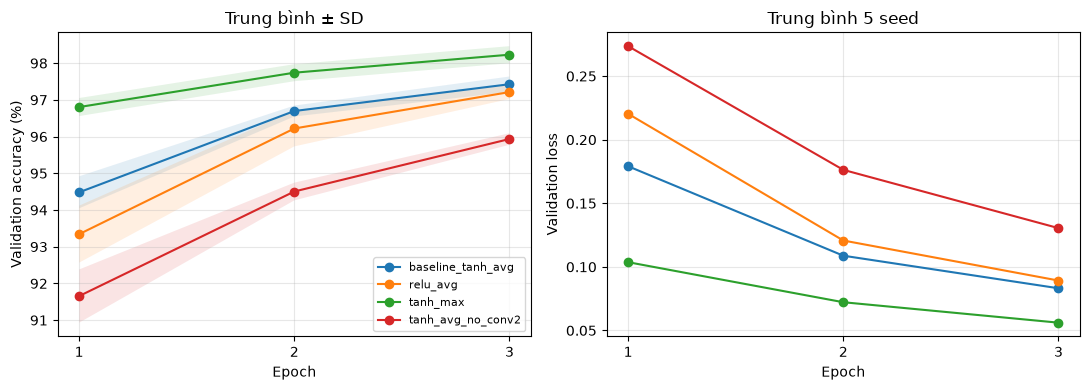

In [14]:
history_rows = []
for (name, seed), frame in histories.items():
    history_rows.append(frame.assign(model=name, seed=seed))
history_runs = pd.concat(history_rows, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in variants:
    group = history_runs[history_runs["model"] == name].groupby("epoch")
    accuracy = group["val_accuracy"].agg(["mean", "std"])
    loss = group["val_loss"].agg(["mean", "std"])
    epochs = accuracy.index.to_numpy()
    axes[0].plot(epochs, 100 * accuracy["mean"], marker="o", label=name)
    axes[0].fill_between(
        epochs,
        100 * (accuracy["mean"] - accuracy["std"]),
        100 * (accuracy["mean"] + accuracy["std"]),
        alpha=0.12,
    )
    axes[1].plot(epochs, loss["mean"], marker="o", label=name)
axes[0].set(xlabel="Epoch", ylabel="Validation accuracy (%)", title="Trung bình ± SD")
axes[1].set(xlabel="Epoch", ylabel="Validation loss", title="Trung bình 5 seed")
for axis in axes:
    axis.set_xticks(range(1, EPOCHS + 1))
    axis.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
accuracy_by_seed = architecture_runs.pivot(
    index="seed", columns="model", values="test_accuracy_pct"
)
lines = [
    "### Phân tích kiến trúc",
    "",
    "Chênh lệch test accuracy dưới đây được ghép cặp theo cùng seed "
    "và tính so với LeNet đối chứng:",
    "",
]
for name in ("relu_avg", "tanh_max", "tanh_avg_no_conv2"):
    paired = accuracy_by_seed[name] - accuracy_by_seed["baseline_tanh_avg"]
    lines.append(
        f"- **{name}**: chênh lệch {paired.mean():+.2f} ± "
        f"{paired.std(ddof=1):.2f} điểm phần trăm."
    )
lines += [
    "",
    "Biến thể bỏ conv2 có số tham số khác đối chứng. "
    "Kết quả không cho phép quy toàn bộ chênh lệch accuracy cho riêng conv2.",
]
display(Markdown("\n".join(lines)))

### Phân tích kiến trúc

Chênh lệch test accuracy dưới đây được ghép cặp theo cùng seed và tính so với LeNet đối chứng:

- **relu_avg**: chênh lệch -0.15 ± 0.42 điểm phần trăm.
- **tanh_max**: chênh lệch +0.77 ± 0.27 điểm phần trăm.
- **tanh_avg_no_conv2**: chênh lệch -1.52 ± 0.35 điểm phần trăm.

Biến thể bỏ conv2 có số tham số khác đối chứng. Kết quả không cho phép quy toàn bộ chênh lệch accuracy cho riêng conv2.

## 4. Vì sao ba epoch đã đạt accuracy cao?

MNIST gồm các chữ số 28×28 đã được chuẩn hóa, còn LeNet là kiến trúc phù hợp với đặc trưng nét viết. Với 50.000 ảnh train và batch 128, mỗi epoch có khoảng **391 bước cập nhật**; ba epoch tương ứng khoảng **1.173 bước cập nhật**, không phải chỉ ba lần điều chỉnh trọng số. Adam có thể giảm loss nhanh trong những epoch đầu. Tuy nhiên, accuracy cao sau ba epoch **không đồng nghĩa đã hội tụ hoàn toàn**.

Để kiểm tra thực nghiệm, huấn luyện một mô hình đối chứng từ đầu trong 10 epoch với seed 42 và so sánh validation accuracy/loss tại epoch 3 và 10. Phép thử này chỉ khảo sát tốc độ học của mô hình đối chứng; bảng so sánh kiến trúc vẫn giữ ngân sách ba epoch như nhau.

In [16]:
convergence_seed = SEEDS[0]
set_seed(convergence_seed)
convergence_model = LeNet(**variants["baseline_tanh_avg"])
convergence_loader = make_loader(
    train_plain, train_indices, shuffle=True, seed=convergence_seed
)
convergence_history = train_model(
    convergence_model, convergence_loader, epochs=CONVERGENCE_EPOCHS
)
display(convergence_history.round(4))

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,train_seconds
0,1,0.4279,0.8796,0.1708,0.9475,0.7063
1,2,0.1327,0.9605,0.1109,0.9664,0.7168
2,3,0.0828,0.9750,0.0767,0.9767,0.6768
3,4,0.0614,0.9815,0.0691,0.9781,0.7107
4,5,0.0482,0.9854,0.0604,0.9817,0.6646
5,6,0.0409,0.9873,0.0542,0.9835,0.6927
6,7,0.0330,0.9899,0.0630,0.9814,0.6969
7,8,0.0277,0.9913,0.0553,0.9835,0.7255
8,9,0.0245,0.9925,0.0552,0.9832,0.6786
9,10,0.0190,0.9945,0.0532,0.9837,0.7044


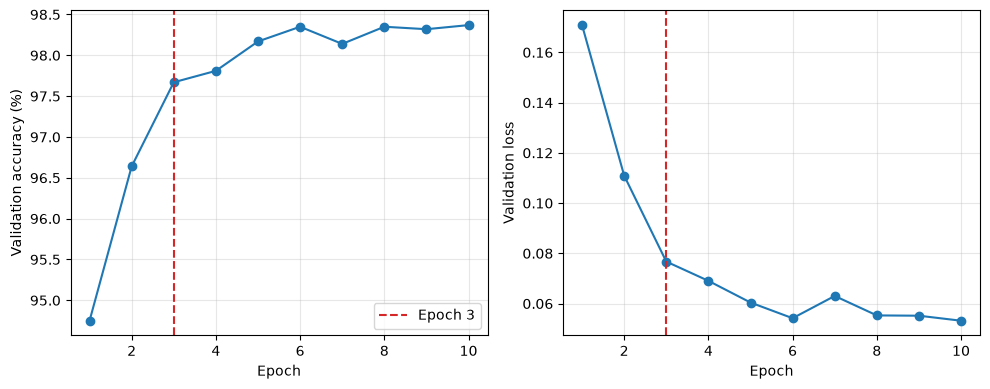

Sau 1,173 bước cập nhật: validation accuracy 97.67%; sau 10 epoch: 98.37%. Mức tăng từ epoch 3 đến 10 là +0.70 điểm phần trăm.

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(
    convergence_history["epoch"],
    100 * convergence_history["val_accuracy"],
    marker="o",
)
axes[1].plot(convergence_history["epoch"], convergence_history["val_loss"], marker="o")
for axis in axes:
    axis.axvline(EPOCHS, color="tab:red", linestyle="--", label="Epoch 3")
    axis.set_xlabel("Epoch")
    axis.grid(alpha=0.3)
axes[0].set_ylabel("Validation accuracy (%)")
axes[1].set_ylabel("Validation loss")
axes[0].legend()
plt.tight_layout()
plt.show()

acc_3 = 100 * convergence_history.loc[EPOCHS - 1, "val_accuracy"]
acc_10 = 100 * convergence_history.loc[CONVERGENCE_EPOCHS - 1, "val_accuracy"]
steps_3 = EPOCHS * math.ceil(len(train_indices) / BATCH_SIZE)
display(
    Markdown(
        f"Sau {steps_3:,} bước cập nhật: validation accuracy {acc_3:.2f}%; "
        f"sau {CONVERGENCE_EPOCHS} epoch: {acc_10:.2f}%. "
        f"Mức tăng từ epoch 3 đến 10 là {acc_10 - acc_3:+.2f} điểm phần trăm."
    )
)

## 5. Tăng cường dữ liệu và độ bền vững

**Giả thuyết:** bổ sung xoay và nhiễu khi train làm giảm mức suy giảm accuracy trên ảnh biến dạng. Mô hình tăng cường dữ liệu giữ nguyên cấu trúc đối chứng và được huấn luyện với cùng năm seed, cùng train/validation split, optimizer và ba epoch. Đối chiếu accuracy ảnh sạch trước khi xem ảnh nhiễu để nhận diện đánh đổi.

In [18]:
clean_accuracy = {
    (row.model, row.seed): row.test_accuracy_pct / 100
    for row in architecture_runs.itertuples(index=False)
}
augmentation_rows = []

for seed in SEEDS:
    set_seed(seed)
    model = LeNet(**variants["baseline_tanh_avg"])
    loader = make_loader(train_augmented, train_indices, shuffle=True, seed=seed)
    history = train_model(model, loader)
    test = evaluate(model, test_loader)

    models[("augmented_tanh_avg", seed)] = model
    histories[("augmented_tanh_avg", seed)] = history
    clean_accuracy[("augmented_tanh_avg", seed)] = test["accuracy"]
    augmentation_rows.append(
        {
            "seed": seed,
            "val_accuracy_pct": 100 * history.iloc[-1]["val_accuracy"],
            "test_accuracy_pct": 100 * test["accuracy"],
            "train_seconds": history["train_seconds"].sum(),
        }
    )
    print(f"Hoàn thành augmentation, seed={seed}")

augmentation_runs = pd.DataFrame(augmentation_rows)

Hoàn thành augmentation, seed=42
Hoàn thành augmentation, seed=43
Hoàn thành augmentation, seed=44
Hoàn thành augmentation, seed=45
Hoàn thành augmentation, seed=46


In [19]:
augmentation_summary = augmentation_runs.agg(
    {
        "val_accuracy_pct": ["mean", "std"],
        "test_accuracy_pct": ["mean", "std"],
        "train_seconds": ["mean", "std"],
    }
)
display(augmentation_summary.round(3))

,val_accuracy_pct,test_accuracy_pct,train_seconds
mean,96.554,97.016,3.575
std,0.239,0.133,0.036


### 5.1. Ảnh kiểm tra với biến dạng có kiểm soát

Ba nhóm biến dạng được áp dụng **chỉ ở test**: Gaussian noise, xoay và Gaussian blur. Với mỗi mức, cả hai mô hình dùng cùng ảnh test và cùng noise seed 2026. Mức 0 là ảnh sạch. Mức suy giảm được tính bằng `accuracy ảnh sạch − accuracy ảnh biến dạng`, đơn vị **điểm phần trăm**; giá trị âm nghĩa là ảnh biến dạng cho accuracy cao hơn ảnh sạch trong lần đo đó.

In [20]:
def corrupt_batch(images, corruption, level, generator):
    if level == 0:
        return images
    if corruption == "noise":
        noise = torch.randn(images.shape, generator=generator) * level
        return (images + noise).clamp(0, 1)
    if corruption == "rotation":
        return torch.stack(
            [
                TF.rotate(image, level, interpolation=InterpolationMode.BILINEAR)
                for image in images
            ]
        )
    if corruption == "blur":
        return TF.gaussian_blur(images, kernel_size=5, sigma=float(level))
    raise ValueError(f"Corruption không hợp lệ: {corruption}")

In [21]:
@torch.inference_mode()
def accuracy_on_corruption(model, corruption, level):
    model.eval()
    generator = torch.Generator().manual_seed(2026)
    correct = total = 0
    for images, labels in test_loader:
        images = corrupt_batch(images, corruption, level, generator).to(DEVICE)
        predictions = model(images).argmax(dim=1).cpu()
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
    return correct / total


corruption_levels = {
    "noise": [0, 0.1, 0.2, 0.3],
    "rotation": [0, 10, 20, 30],
    "blur": [0, 0.5, 1.0, 1.5],
}

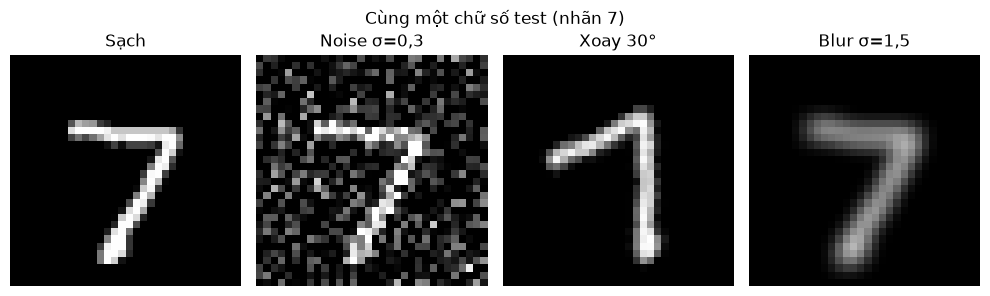

In [22]:
image, label = test_data[0]
examples = [
    ("Sạch", image),
    (
        "Noise σ=0,3",
        corrupt_batch(image[None], "noise", 0.3, torch.Generator().manual_seed(2026))[
            0
        ],
    ),
    ("Xoay 30°", corrupt_batch(image[None], "rotation", 30, torch.Generator())[0]),
    ("Blur σ=1,5", corrupt_batch(image[None], "blur", 1.5, torch.Generator())[0]),
]
fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for axis, (title, example) in zip(axes, examples, strict=True):
    axis.imshow(example.squeeze(), cmap="gray", vmin=0, vmax=1)
    axis.set_title(title)
    axis.axis("off")
plt.suptitle(f"Cùng một chữ số test (nhãn {label})")
plt.tight_layout()
plt.show()

In [23]:
robustness_rows = []
for seed in SEEDS:
    for name in ("baseline_tanh_avg", "augmented_tanh_avg"):
        model = models[(name, seed)]
        clean = clean_accuracy[(name, seed)]
        for corruption, levels in corruption_levels.items():
            for level in levels:
                accuracy = accuracy_on_corruption(model, corruption, level)
                robustness_rows.append(
                    {
                        "seed": seed,
                        "model": name,
                        "corruption": corruption,
                        "level": level,
                        "accuracy_pct": 100 * accuracy,
                        "degradation_pp": 100 * (clean - accuracy),
                    }
                )

robustness_runs = pd.DataFrame(robustness_rows)

In [24]:
robustness_summary = (
    robustness_runs.groupby(["model", "corruption", "level"], sort=False)
    .agg(
        accuracy_mean=("accuracy_pct", "mean"),
        accuracy_sd=("accuracy_pct", "std"),
        degradation_mean=("degradation_pp", "mean"),
        degradation_sd=("degradation_pp", "std"),
    )
    .reset_index()
)
display(robustness_summary.round(2))

,model,corruption,level,accuracy_mean,accuracy_sd,degradation_mean,degradation_sd
0,baseline_tanh_avg,noise,0.0,97.61,0.30,0.00,0.00
1,baseline_tanh_avg,noise,0.1,96.38,0.17,1.24,0.41
2,baseline_tanh_avg,noise,0.2,85.35,2.50,12.26,2.72
3,baseline_tanh_avg,noise,0.3,72.25,4.45,25.37,4.40
4,baseline_tanh_avg,rotation,0.0,97.61,0.30,0.00,0.00
5,baseline_tanh_avg,rotation,10.0,96.29,0.16,1.32,0.24
6,baseline_tanh_avg,rotation,20.0,89.99,0.56,7.63,0.83
7,baseline_tanh_avg,rotation,30.0,75.00,1.06,22.62,1.34
8,baseline_tanh_avg,blur,0.0,97.61,0.30,0.00,0.00
9,baseline_tanh_avg,blur,0.5,97.53,0.30,0.09,0.04


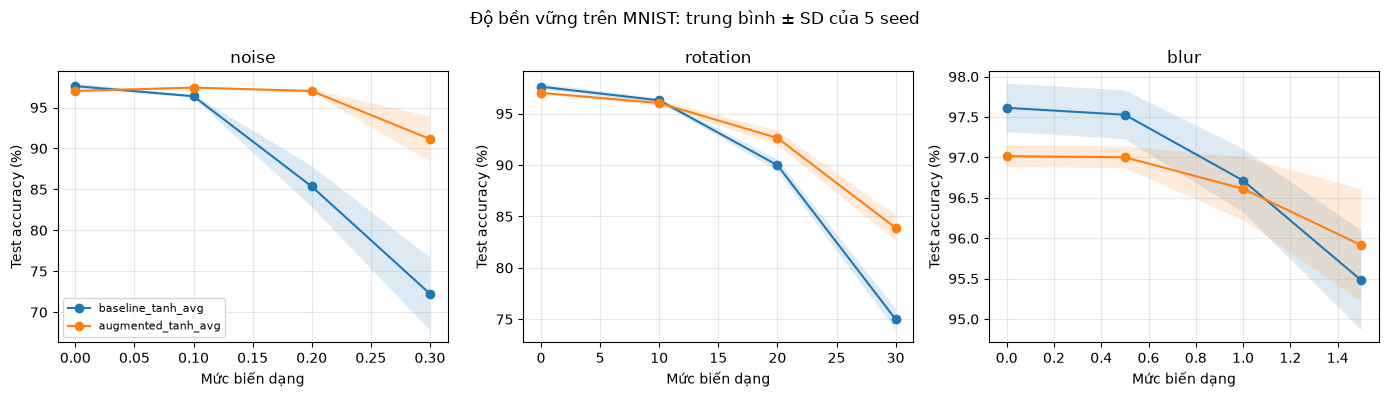

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, corruption in zip(axes, corruption_levels, strict=True):
    for name in ("baseline_tanh_avg", "augmented_tanh_avg"):
        data = robustness_summary[
            (robustness_summary["model"] == name)
            & (robustness_summary["corruption"] == corruption)
        ]
        levels = data["level"].to_numpy()
        mean = data["accuracy_mean"].to_numpy()
        sd = data["accuracy_sd"].to_numpy()
        axis.plot(levels, mean, marker="o", label=name)
        axis.fill_between(levels, mean - sd, mean + sd, alpha=0.15)
    axis.set(xlabel="Mức biến dạng", ylabel="Test accuracy (%)", title=corruption)
    axis.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.suptitle("Độ bền vững trên MNIST: trung bình ± SD của 5 seed")
plt.tight_layout()
plt.show()

## 6. Thời gian suy luận

Đo latency với batch=1 sau 20 lần warmup và 100 lần đo cho từng mô hình/seed. GPU được đồng bộ ở mỗi lần đo. Đây là thời gian của lời gọi PyTorch; không bao gồm khởi tạo mô hình và đọc ảnh. Bảng cuối hiển thị trung bình ± độ lệch chuẩn của **median latency** qua năm seed.

In [26]:
@torch.inference_mode()
def measure_latency(model, repeats=100, warmup=20):
    model.eval()
    image = test_data[0][0].unsqueeze(0).to(DEVICE)
    for _ in range(warmup):
        model(image)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    durations_ms = []
    for _ in range(repeats):
        started = time.perf_counter()
        model(image)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        durations_ms.append(1_000 * (time.perf_counter() - started))
    return np.median(durations_ms), np.percentile(durations_ms, 95)

In [27]:
latency_rows = []
for seed in SEEDS:
    for name in (*variants, "augmented_tanh_avg"):
        median_ms, p95_ms = measure_latency(models[(name, seed)])
        latency_rows.append(
            {
                "seed": seed,
                "model": name,
                "median_ms": median_ms,
                "p95_ms": p95_ms,
            }
        )

latency_runs = pd.DataFrame(latency_rows)
latency_summary = latency_runs.groupby("model", sort=False).agg(
    median_mean_ms=("median_ms", "mean"),
    median_sd_ms=("median_ms", "std"),
    p95_mean_ms=("p95_ms", "mean"),
)
display(latency_summary.round(3))

,median_mean_ms,median_sd_ms,p95_mean_ms
model,,,
baseline_tanh_avg,0.062,0.000,0.081
relu_avg,0.063,0.000,0.111
tanh_max,0.064,0.002,0.115
tanh_avg_no_conv2,0.050,0.001,0.098
augmented_tanh_avg,0.062,0.001,0.113


## 7. Đánh giá chéo trên EMNIST Digits

EMNIST Digits có 10 lớp chữ số 0–9 giống MNIST. Dùng **tập test EMNIST Digits** để đánh giá mô hình đã huấn luyện trên MNIST, không fine-tune trên EMNIST. Ảnh EMNIST gốc được lưu theo hướng chuyển vị; áp dụng phép chuyển vị trước khi pad và đưa về tensor, rồi hiển thị mẫu để kiểm tra nhãn/hướng ảnh. Đây là phép thử chuyển bộ dữ liệu, không phải đánh giá ảnh chụp điện thoại.

Nguồn dữ liệu và lưu ý về hướng ảnh: [NIST EMNIST](https://www.nist.gov/itl/products-and-services/emnist-dataset), [TensorFlow Datasets EMNIST](https://github.com/tensorflow/datasets/blob/master/docs/catalog/emnist.md).

100%|██████████| 562M/562M [00:06<00:00, 92.2MB/s] 


EMNIST Digits test: 40,000 ảnh; 10 lớp


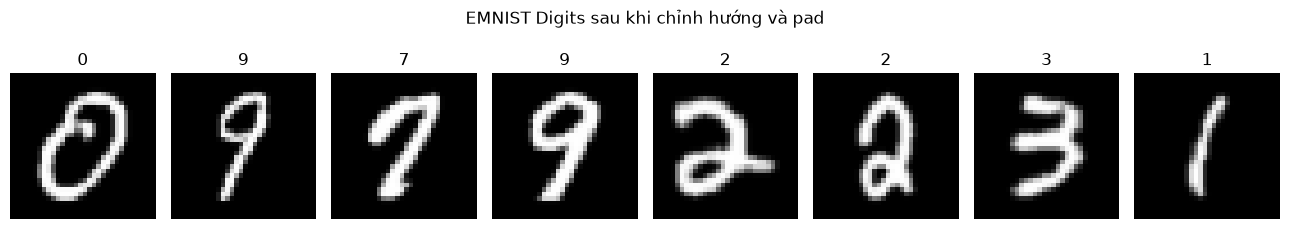

In [28]:
emnist_transform = transforms.Compose(
    [
        transforms.Lambda(lambda image: image.transpose(Image.Transpose.TRANSPOSE)),
        transforms.Pad(2),
        transforms.ToTensor(),
    ]
)
emnist_test = datasets.EMNIST(
    "data", split="digits", train=False, download=True, transform=emnist_transform
)
emnist_loader = make_loader(emnist_test)
assert set(emnist_test.targets.unique().tolist()) == set(range(10))
print(f"EMNIST Digits test: {len(emnist_test):,} ảnh; 10 lớp")

fig, axes = plt.subplots(1, 8, figsize=(13, 2.5))
for axis, index in zip(axes, range(8), strict=True):
    image, label = emnist_test[index]
    axis.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
    axis.set_title(str(label))
    axis.axis("off")
plt.suptitle("EMNIST Digits sau khi chỉnh hướng và pad")
plt.tight_layout()
plt.show()

In [29]:
emnist_rows = []
for seed in SEEDS:
    for name in ("baseline_tanh_avg", "augmented_tanh_avg"):
        result = evaluate(models[(name, seed)], emnist_loader)
        mnist_accuracy = 100 * clean_accuracy[(name, seed)]
        emnist_accuracy = 100 * result["accuracy"]
        emnist_rows.append(
            {
                "seed": seed,
                "model": name,
                "mnist_accuracy_pct": mnist_accuracy,
                "emnist_accuracy_pct": emnist_accuracy,
                "cross_dataset_drop_pp": mnist_accuracy - emnist_accuracy,
            }
        )

emnist_runs = pd.DataFrame(emnist_rows)
emnist_summary = emnist_runs.groupby("model", sort=False).agg(
    mnist_mean=("mnist_accuracy_pct", "mean"),
    mnist_sd=("mnist_accuracy_pct", "std"),
    emnist_mean=("emnist_accuracy_pct", "mean"),
    emnist_sd=("emnist_accuracy_pct", "std"),
    drop_mean=("cross_dataset_drop_pp", "mean"),
    drop_sd=("cross_dataset_drop_pp", "std"),
)
display(emnist_summary.round(2))

,mnist_mean,mnist_sd,emnist_mean,emnist_sd,drop_mean,drop_sd
model,,,,,,
baseline_tanh_avg,97.61,0.30,81.69,1.48,15.92,1.44
augmented_tanh_avg,97.02,0.13,83.18,1.52,13.84,1.50


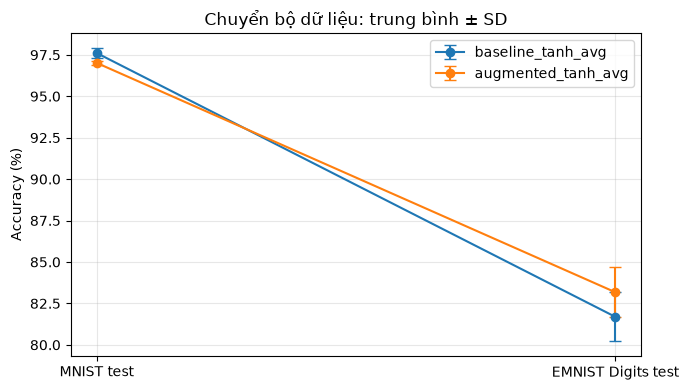

In [30]:
fig, axis = plt.subplots(figsize=(7, 4))
for name in emnist_summary.index:
    row = emnist_summary.loc[name]
    axis.errorbar(
        ["MNIST test", "EMNIST Digits test"],
        [row["mnist_mean"], row["emnist_mean"]],
        yerr=[row["mnist_sd"], row["emnist_sd"]],
        marker="o",
        capsize=4,
        label=name,
    )
axis.set(ylabel="Accuracy (%)", title="Chuyển bộ dữ liệu: trung bình ± SD")
axis.grid(alpha=0.3)
axis.legend()
plt.tight_layout()
plt.show()

## 8. Thảo luận kết quả

Phần tổng hợp dưới đây lấy trực tiếp từ các bảng kết quả năm seed: độ chính xác trên MNIST sạch, đáp ứng với ba nhóm biến dạng và độ chính xác khi chuyển sang EMNIST Digits.

In [31]:
severe_levels = {"noise": 0.3, "rotation": 30, "blur": 1.5}
clean_base = architecture_summary.loc["baseline_tanh_avg", "test_mean"]
clean_aug = augmentation_runs["test_accuracy_pct"].mean()
emnist_base = emnist_summary.loc["baseline_tanh_avg", "emnist_mean"]
emnist_aug = emnist_summary.loc["augmented_tanh_avg", "emnist_mean"]
lines = [
    "### Kết quả chính",
    "",
    f"Accuracy MNIST sạch (5 seed): đối chứng {clean_base:.2f}%; "
    f"augmentation {clean_aug:.2f}%.",
    "",
]
for corruption, level in severe_levels.items():
    subset = robustness_summary[
        (robustness_summary["corruption"] == corruption)
        & (robustness_summary["level"] == level)
    ].set_index("model")
    base = subset.loc["baseline_tanh_avg"]
    aug = subset.loc["augmented_tanh_avg"]
    lines.append(
        f"- **{corruption}, mức {level:g}**: đối chứng "
        f"{base['accuracy_mean']:.2f} ± {base['accuracy_sd']:.2f}%; "
        f"augmentation {aug['accuracy_mean']:.2f} ± "
        f"{aug['accuracy_sd']:.2f}%."
    )
lines.extend(
    [
        "",
        f"EMNIST Digits: đối chứng {emnist_base:.2f}%; "
        f"augmentation {emnist_aug:.2f}% "
        "(đều là mô hình chỉ huấn luyện trên MNIST).",
        "",
        "Các chênh lệch là kết quả của năm seed trên cùng một phép chia dữ liệu. "
        "Không suy ra rằng một biến thể luôn vượt trội ở mọi tập chữ viết.",
    ]
)
display(Markdown("\n".join(lines)))

### Kết quả chính

Accuracy MNIST sạch (5 seed): đối chứng 97.61%; augmentation 97.02%.

- **noise, mức 0.3**: đối chứng 72.25 ± 4.45%; augmentation 91.16 ± 2.76%.
- **rotation, mức 30**: đối chứng 75.00 ± 1.06%; augmentation 83.89 ± 1.24%.
- **blur, mức 1.5**: đối chứng 95.48 ± 0.62%; augmentation 95.91 ± 0.70%.

EMNIST Digits: đối chứng 81.69%; augmentation 83.18% (đều là mô hình chỉ huấn luyện trên MNIST).

Các chênh lệch là kết quả của năm seed trên cùng một phép chia dữ liệu. Không suy ra rằng một biến thể luôn vượt trội ở mọi tập chữ viết.

## 9. Giới hạn và tài liệu tham khảo

- Năm seed phản ánh biến thiên do khởi tạo, shuffle và augmentation; train/validation split vẫn cố định. Nếu muốn đánh giá biến thiên theo dữ liệu, cần lặp cả phép chia tập.
- Bảng kiến trúc dùng cùng ngân sách ba epoch; đường học 10 epoch chỉ khảo sát một mô hình đối chứng với một seed. Không dùng đường học này để khẳng định mọi biến thể đều hội tụ sau ba epoch.
- Phép thử Gaussian noise, xoay và blur là biến dạng nhân tạo. EMNIST Digits bổ sung một bộ chữ viết tay khác nhưng chưa đại diện cho ảnh chụp thực tế.
- Bỏ conv2 đồng thời đổi số tham số; cần kiểm soát kích thước mô hình nếu muốn cô lập vai trò của riêng tầng convolution.
- Latency phụ thuộc CPU/GPU, batch, precision và quy trình tiền xử lý. Số đo trong notebook áp dụng cho môi trường thực thi được in ở đầu bài.

**Tài liệu tham khảo:** [LeNet-5](http://yann.lecun.com/exdb/lenet/); [MNIST trong torchvision](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html); [EMNIST — NIST](https://www.nist.gov/itl/products-and-services/emnist-dataset); [EMNIST trong torchvision](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.EMNIST.html); [PyTorch reproducibility](https://pytorch.org/docs/stable/notes/randomness.html).